# День 08. Упражнение 01
# Бинарный классификатор. SVM. Дерево решений

## 0. Импорты

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## 1. Предобработка и визуализация логистической регрессии

Прочитай файл am_pm.csv в DataFrame из предыдущего упражнения.

Прочитай файл am_pm.csv в DataFrame из предыдущего упражнения.

In [3]:
df = pd.read_csv("../data/am_pm.csv")
df.head(3)

,date,am,pm,target,predict
0,2020-04-17,21,2,working_day,weekend
1,2020-04-18,1,68,weekend,working_day
2,2020-04-19,18,15,weekend,working_day


1. Построй график, где по оси x — am, по оси y — pm, точки — это дни, цвет зависит от целевой переменной.

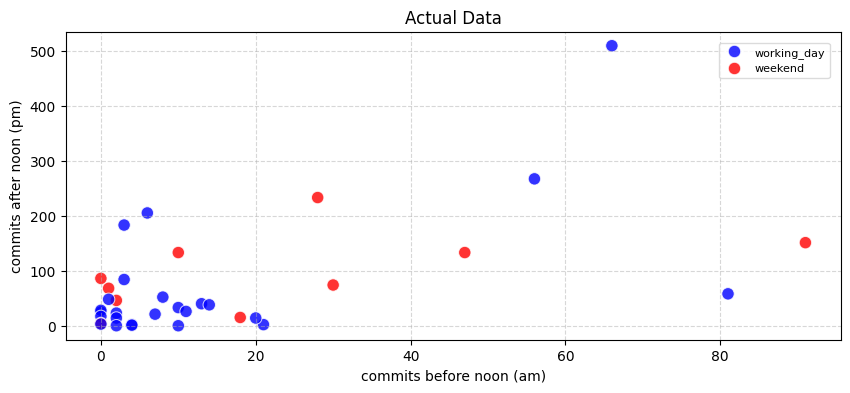

In [ ]:
def draw_plot(df_name, column, title_name, am_line=None, pm_line=None, svc_mesh=None):
    # upd. добавила param svc_mesh: кортеж (xx, yy, Z) для нелинейных границ SVC
    # если  нелинейная сетка SVC передана, рисуем её контур в первую очередь
    if svc_mesh is not None:
        xx, yy, Z = svc_mesh
        plt.contour(
            xx, yy, Z, levels=[0.5], colors="green", linestyles="-.", linewidths=2
        )

    plt.figure(figsize=(10, 4))
    sns.scatterplot(
        data=df_name,
        x="am",
        y="pm",
        hue=column,
        palette={"working_day": "b", "weekend": "r"},
        alpha=0.8,
        s=80,
    )
    if am_line is not None and pm_line is not None:
        plt.plot(
            am_line,
            pm_line,
            color="green",
            linestyle="-.",
            linewidth=2,
            label="Decision Boundary",
        )

    plt.xlabel("commits before noon (am)", fontsize=10)
    plt.ylabel("commits after noon (pm)", fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.title(title_name)
    plt.legend(
        fontsize=8,
        loc="upper right",
        borderaxespad=1,
        frameon=True,
        facecolor="white",
        edgecolor="lightgray",
    )
    plt.show()


draw_plot(df, "target", "Actual Data", am_line=None, pm_line=None)

2. Добавь на график границу решений логистической регрессии.

В логистической регрессии логарифм шансов (логит) объекта равен линейной комбинации его признаков $$ \ln \left( \frac{p}{1 - p} \right) = w_1 \cdot am + w_2 \cdot pm $$

Модель относит объект к классу 1 (выходной), если вероятность p >= 0.5 или к будням, если p < 0.5. Точка идеального баланса («ни туда, ни сюда») — это p = 0.5

В точке баланса мы получаем зануление логита: $\ln \left( \frac{0.5}{1 - 0.5} \right) = \ln \left( \frac{0.5}{0.5} \right) = \ln(1) = 0$.

Раз логарифм шансов (логит) в точке разделения классов равен нулю, мы получаем уравнение разделяющей плоскости:

$$ w_1 \cdot am + w_2 \cdot pm = 0 $$

Перенесем слагаемое с признаком $am$ в правую часть уравнения, изменив его знак на противоположный:

$$ w_2 \cdot pm = -w_1 \cdot am $$

Разделим обе части уравнения на коэффициент $w_2$, чтобы выразить переменную $pm$ (ось $y$) через переменную $am$ (ось $x$):

$$ pm = -\frac{w_1}{w_2} \cdot am $$


In [5]:
# переобучение модели для извлечения коэффициентов
X = df[["am", "pm"]]
y = (df["target"] == "weekend").astype(int)
model = LogisticRegression(random_state=21, fit_intercept=False)
model.fit(X, y)
w1, w2 = model.coef_[0]
print(w1, w2)

0.000386526615277099 -0.0029806573907424157


In [6]:
# Генерируем массив точек по оси X (от 0 до максимума в am) для построения линии
# Метод np.linspace() из библиотеки NumPy генерирует массив из чисел, равномерно распределённых в заданном интервале
# 0 (Старт): Начало отсчёта. Мы начинаем строить линию от самого левого края графика — от нуля коммитов.df["am"].max() (Стоп): Конечная точка. Линия будет строиться ровно до самого правого края графика, где находится день с максимальным количеством утренних коммитов (на вашем графике это чуть дальше 90).100 (Количество точек): Указывает, на сколько равных отрезков нужно разбить этот путь. То есть внутри массива am_line будет лежать 100 чисел: [0.0, 0.91, 1.82, ..., 91.0].
am_line = np.linspace(0, df["am"].max(), 100)
# Вычисляем Y (pm) по формуле разделяющей границы
pm_line = -(w1 / w2) * am_line

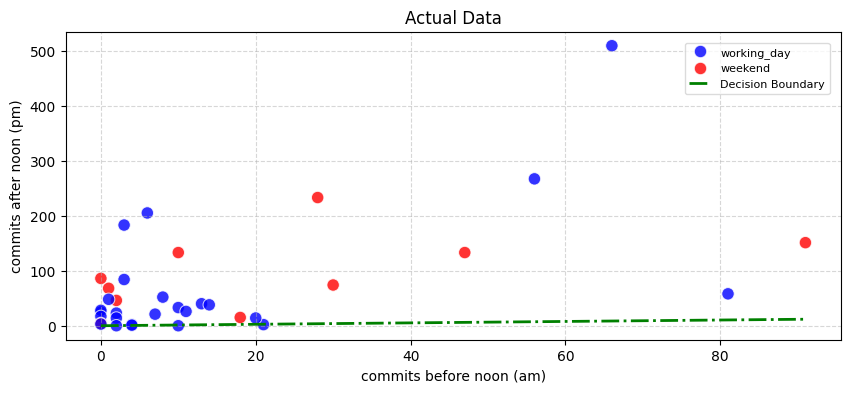

In [7]:
draw_plot(df, "target", "Actual Data", am_line=am_line, pm_line=pm_line)

3. Построй тот же график (с границей), но на этот раз цвет должен зависеть от предсказаний.
Теперь тебе должно быть понятно, как работает логистическая регрессия.
Да, модель провела разграничительную линию и все точки, которые оказались выше она отнесла к working_day (покрасила в синий), а все что под ней или на ней к weekend (красный).

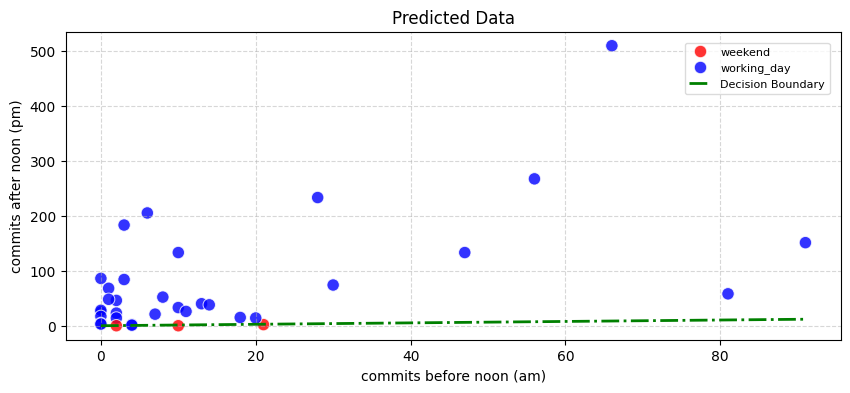

In [8]:
draw_plot(df, "predict", "Predicted Data", am_line=am_line, pm_line=pm_line)

## 2. Стандартизация и логистическая регрессия

Линейные модели чувствительны к масштабу переменных. Масштабирование признаков помогает модели проще находить оптимальное решение.

1. Применись StandardScaler к X и обучи логистическую регрессию снова с теми же параметрами.

In [9]:
# Масштабируем признаки
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
# Создаем новый DataFrame только для масштабированных данных
df_scaled = pd.DataFrame(X_scaled, columns=["am", "pm"])
df_scaled["target"] = df["target"]

In [11]:
# Обучаем модель с теми же параметрами
model_scaled = LogisticRegression(random_state=21, fit_intercept=False)
model_scaled.fit(X_scaled, y)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",False
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",21
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mult

In [12]:
# Делаем предсказания и добавляем в df_scaled
y_pred_scaled = model_scaled.predict(X_scaled)
df_scaled["predict"] = np.where(y_pred_scaled == 1, "weekend", "working_day")

2. Вычисли accuracy для новой модели. Стала ли она лучше наивного классификатора, предсказывающего самый частый класс?

In [13]:
# Считаем новую точность
new_accuracy = accuracy_score(y, y_pred_scaled)
print(new_accuracy)

0.7428571428571429


ответ на вопрос: naive_accuracy из ex00 была = 0.7142857142857143, так что да, accuracy новой модели выше.

3. Построй описанные выше графики, но уже для новой модели.

In [14]:
w1, w2 = model_scaled.coef_[0]  # Берем коэффициенты новой модели
# Генерируем линию в границах масштабированного 'am'
am_line_scaled = np.linspace(df_scaled["am"].min(), df_scaled["am"].max(), 100)
pm_line_scaled = -(w1 / w2) * am_line_scaled

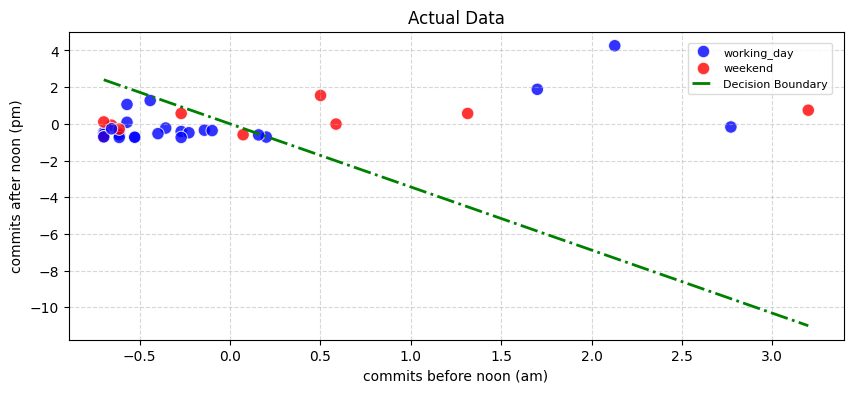

In [ ]:
draw_plot(
    df_scaled, "target", "Actual Data", am_line=am_line_scaled, pm_line=pm_line_scaled
)

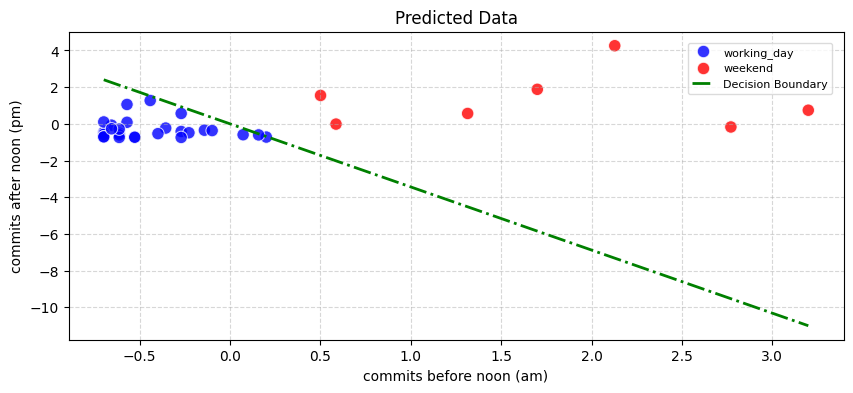

In [ ]:
draw_plot(
    df_scaled,
    "predict",
    "Predicted Data",
    am_line=am_line_scaled,
    pm_line=pm_line_scaled,
)

## 3. SVM

1. Применись модель SVC к масштабированному DataFrame с параметрами probability=True, random_state=21.
2. Вычисли accuracy.
3. Попробуй разные ядра и найди то, которое дает наилучшую точность.
4. Построй оба графика снова с границей решений, чтобы увидеть, как работает этот алгоритм.

In [19]:
df_scaled.head(3)

,am,pm,target,predict
0,0.200690,-0.719904,working_day,working_day
1,-0.655914,-0.071822,weekend,working_day
2,0.072199,-0.592251,weekend,working_day


In [40]:
kernels = ["linear", "poly", "rbf", "sigmoid"]
accuracy_history = {}
trained_models = {}

for k in kernels:
    model_svc = SVC(kernel=k, probability=True, random_state=21)
    model_svc.fit(X_scaled, y)
    y_pred_svc = model_svc.predict(X_scaled)
    acc = accuracy_score(y, y_pred_svc)
    accuracy_history[k] = acc
    trained_models[k] = model_svc

print(accuracy_history)
highest_accuracy = max(accuracy_history.values())
best_kernels = [k for k, v in accuracy_history.items() if v == highest_accuracy]
print(f"Наилучшая точность для модели SVC: {highest_accuracy}")
print(f"Ядро с такой точностью: {', '.join(best_kernels)}")
print(trained_models)

# В машинном обучении при одинаковой точности принято отдавать предпочтение именно rbf, поскольку оно строит более плавные, стабильные и естественные замкнутые границы (овалы/круги), в то время как полиномиальное ядро (poly) может сильно изламывать линию и улетать в бесконечность на краях графика.

{'linear': 0.7142857142857143, 'poly': 0.7428571428571429, 'rbf': 0.7428571428571429, 'sigmoid': 0.6857142857142857}
Наилучшая точность для модели SVC: 0.7428571428571429
Ядро с такой точностью: poly, rbf
{'linear': SVC(kernel='linear', probability=True, random_state=21), 'poly': SVC(kernel='poly', probability=True, random_state=21), 'rbf': SVC(probability=True, random_state=21), 'sigmoid': SVC(kernel='sigmoid', probability=True, random_state=21)}


In [ ]:
final_svc = trained_models["rbf"]
final_svc

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [ ]:
df_scaled["predict_svc"] = np.where(
    final_svc.predict(X_scaled) == 1, "weekend", "working_day"
)
df_scaled.head(3)

,am,pm,target,predict,predict_svc
0,0.200690,-0.719904,working_day,working_day,working_day
1,-0.655914,-0.071822,weekend,working_day,working_day
2,0.072199,-0.592251,weekend,working_day,working_day


In [ ]:
# ГЕНЕРИРУЕМ СЕТКУ ДЛЯ КРИВОЛИНЕЙНОЙ ГРАНИЦЫ
# Определяем границы графика с запасом
x_min, x_max = df_scaled["am"].min() - 0.5, df_scaled["am"].max() + 0.5
y_min, y_max = df_scaled["pm"].min() - 0.5, df_scaled["pm"].max() + 0.5

In [45]:
# Создаем плотную сетку 500х500 точек
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

In [ ]:
# Просим модель предсказать класс (0 или 1) для каждой микро-точки этой сетки
Z = final_svc.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)  # Возвращаем форму сетки
# Упаковываем сетку в один кортеж для передачи в функцию
svc_mesh_data = (xx, yy, Z)

## 4. Дерево решений

1. Применись DecisionTreeClassifier к масштабированному DataFrame с параметрами max_depth=4, random_state=42.
2. Вычисли accuracy.
3. Попробуй разные значения max_depth.
4. Построй оба графика снова с границей решений, чтобы увидеть, как работает этот алгоритм.
5. С помощью метода .plot_tree() визуализируй само дерево решений. Это еще один способ понять, как работает алгоритм.
6. Сколько листьев на визуализированном дереве обозначают рабочие дни? Напиши ответ в markdown-ячейке в конце раздела.